In [32]:
from pathlib import Path
import sys
import os
import json
import random
import hashlib
import math
from collections import defaultdict
from datetime import datetime

candidates = [Path.cwd(), *Path.cwd().parents, Path.cwd() / "working_model"]
PROJECT_ROOT = next((p for p in candidates if (p / "preprocessing/dataset.py").is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Open this notebook inside the working_model project.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
RUN_DIR = PROJECT_ROOT / "outputs/notebooks" / datetime.now().strftime("learning-%Y%m%d-%H%M%S-%f")
RUN_DIR.mkdir(parents=True, exist_ok=False)
os.environ["MPLCONFIGDIR"] = str(PROJECT_ROOT / "outputs/matplotlib-cache")
import torch
import torchvision
from PIL import Image, ImageDraw, ImageEnhance, ImageFilter
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision.transforms.functional import to_tensor, to_pil_image
from torchvision.models.detection import (
    FasterRCNN_MobileNet_V3_Large_320_FPN_Weights,
    fasterrcnn_mobilenet_v3_large_320_fpn,
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display
%matplotlib inline
torch.set_num_threads(2)
torch.manual_seed(42)
random.seed(42)
device = torch.device("cpu")
torch.hub.set_dir(str(PROJECT_ROOT / "checkpoints/torch_hub"))
print("Python:", sys.executable)
print("PyTorch:", torch.__version__, "| Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available(), "| This lesson uses:", device)
print("Outputs:", RUN_DIR)

Python: c:\Users\JT GAMING\Desktop\Mlops\.venv312\Scripts\python.exe
PyTorch: 2.14.1+cpu | Torchvision: 0.29.1+cpu
CUDA available: False | This lesson uses: cpu
Outputs: c:\Users\JT GAMING\Desktop\Model working\working_model\outputs\notebooks\learning-20261014-041308-553200


In [33]:
%pip install torch torchvision

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [34]:
DEFAULT_DATA_ROOT = PROJECT_ROOT / "data/raw/DeepPCB/PCBData"
DEFAULT_SPLIT_PATH = PROJECT_ROOT / "data/splits/deeppcb.json"
CLASS_NAMES = {1: "Open", 2: "Short", 3: "Mousebite", 4: "Spur", 5: "Copper", 6: "Pin hole"}
rows = [row for row in (DEFAULT_DATA_ROOT / "trainval.txt").read_text().splitlines() if row.strip()]
base_name, annotation_name = rows[0].split()
base = Path(base_name)
image_path = DEFAULT_DATA_ROOT / base.with_name(base.stem + "_test.jpg")
reference_path = DEFAULT_DATA_ROOT / base.with_name(base.stem + "_temp.jpg")
annotation_path = DEFAULT_DATA_ROOT / annotation_name
print("Training/validation examples:", len(rows))
print("First split entry:", rows[0])
print("Defect classes:", CLASS_NAMES)
print("Annotation rows:\n" + annotation_path.read_text())

Training/validation examples: 1000
First split entry: group20085/20085/20085000.jpg group20085/20085_not/20085000.txt
Defect classes: {1: 'Open', 2: 'Short', 3: 'Mousebite', 4: 'Spur', 5: 'Copper', 6: 'Pin hole'}
Annotation rows:
409 394 435 422 3
275 383 319 417 3
8 163 36 191 4
244 151 270 182 5
338 519 364 543 6
476 460 502 481 4



In [35]:
def enhance_image(image):
    # better visualization without changing the orgianal image
    image = ImageEnhance.Contrast(image).enhance(1.25)
    image = ImageEnhance.Sharpness(image).enhance(1.4)
    image = image.filter(ImageFilter.UnsharpMask(radius=1, percent=80, threshold=3))
    # print(image)
    return image
print("Enhancement function ready.")



Enhancement function ready.


In [ ]:
class DeepPCBDataset(Dataset):
    def __init__(self, root=DEFAULT_DATA_ROOT, split="trainval"):
        if split not in {"trainval", "test"}:
            raise ValueError("split must be 'trainval' or 'test'")

        self.root = Path(root)
        self.samples = []
        split_path = self.root / f"{split}.txt"
        # simple iterator
        for line_number, line in enumerate(split_path.read_text().splitlines(), 1):
            if not line.strip():
                continue
            fields = line.split()
            if len(fields) != 2:
                raise ValueError(f"{split_path}:{line_number}: expected two paths")
            base = Path(fields[0])
            image_path = self.root / base.with_name(f"{base.stem}_test.jpg")
            label_path = self.root / fields[1]
            for path in (image_path, label_path):
                if not path.is_file():
                    raise FileNotFoundError(f"Missing dataset file: {path}")

            self.samples.append((image_path, label_path))

        if not self.samples:
            raise ValueError(f"No samples in {split_path}")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        image_path, label_path = self.samples[index]

        with Image.open(image_path) as source:
            image = source.convert("RGB")

        image = enhance_image(image)
        width, height = image.size
        boxes, labels = [], []
        for line_number, line in enumerate(label_path.read_text().splitlines(), 1):
            if not line.strip():
                continue
            try:
                x1, y1, x2, y2, class_id = map(int, line.split())
            except ValueError as error:
                raise ValueError(
                    f"{label_path}:{line_number}: expected five integers"
                ) from error
            if class_id not in CLASS_NAMES:
                raise ValueError(f"{label_path}:{line_number}: invalid class {class_id}")
            if not (0 <= x1 < x2 <= width and 0 <= y1 < y2 <= height):
                raise ValueError(f"{label_path}:{line_number}: invalid bounding box")
            boxes.append([x1, y1, x2, y2])
            labels.append(class_id)
        """here we are converting the boxes and labels to tensors and creating a target dictionary that contains the bounding boxes, labels, image ID, area of the boxes, and a flag indicating whether the boxes are crowded or not. This target dictionary will be used for training object detection models."""
        boxes = torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4)
        target = {
            "boxes": boxes,
            "labels": torch.tensor(labels, dtype=torch.int64),
            "image_id": torch.tensor([index], dtype=torch.int64),
            "area": (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1]),
            "iscrowd": torch.zeros(len(labels), dtype=torch.int64),
        }

        return to_tensor(image), target

In [37]:
dataset = DeepPCBDataset()
image, target = dataset[0]
print("Examples:", len(dataset))
print("Image:", tuple(image.shape), image.dtype, "range:", (float(image.min()), float(image.max())))
for name, value in target.items():
    print(f"{name}: shape={tuple(value.shape)}, values={value.tolist()}")
assert image.shape[0] == 3
assert len(target["boxes"]) == len(target["labels"])

Examples: 1000
Image: (3, 640, 640) torch.float32 range: (0.0, 1.0)
boxes: shape=(6, 4), values=[[409.0, 394.0, 435.0, 422.0], [275.0, 383.0, 319.0, 417.0], [8.0, 163.0, 36.0, 191.0], [244.0, 151.0, 270.0, 182.0], [338.0, 519.0, 364.0, 543.0], [476.0, 460.0, 502.0, 481.0]]
labels: shape=(6,), values=[3, 3, 4, 5, 6, 4]
image_id: shape=(1,), values=[0]
area: shape=(6,), values=[728.0, 1496.0, 784.0, 806.0, 624.0, 546.0]
iscrowd: shape=(6,), values=[0, 0, 0, 0, 0, 0]


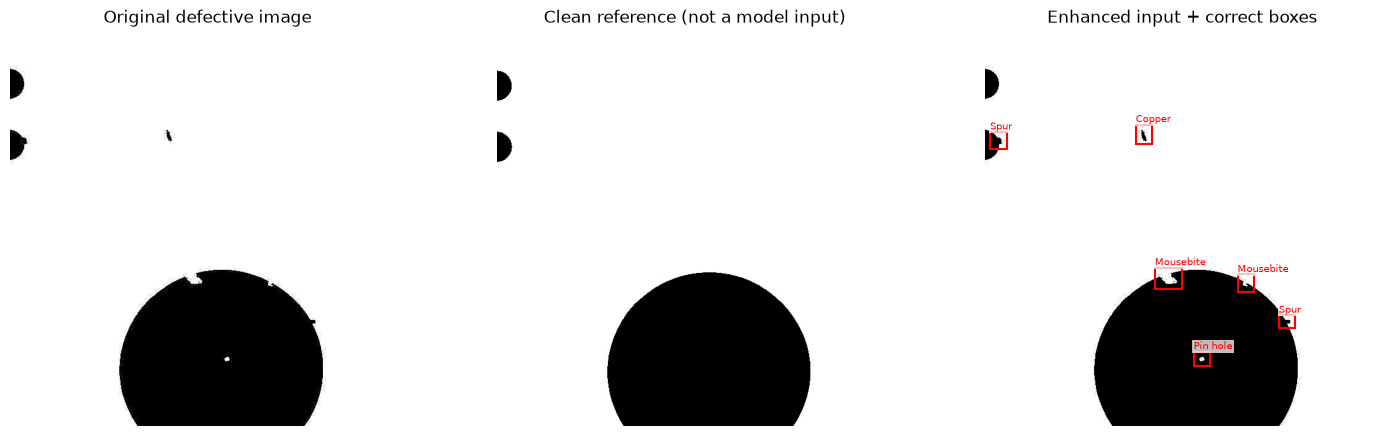

In [38]:
def show_boxes(ax, image_tensor, boxes, labels, title, scores=None):
    ax.imshow(to_pil_image(image_tensor))
    for index, (box, label) in enumerate(zip(boxes.tolist(), labels.tolist())):
        x1, y1, x2, y2 = box
        ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, fill=False, edgecolor="red", linewidth=1.5))
        text = CLASS_NAMES[label]
        if scores is not None:
            text += f" {float(scores[index]):.2f}"
        ax.text(x1, max(0, y1-4), text, color="red", fontsize=7,
                bbox={"facecolor": "white", "alpha": 0.75, "pad": 1, "edgecolor": "none"})
    ax.set_title(title)
    ax.axis("off")

with Image.open(image_path) as source:
    original = source.convert("RGB")
with Image.open(reference_path) as source:
    reference = source.convert("RGB")
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(original); axes[0].set_title("Original defective image"); axes[0].axis("off")
axes[1].imshow(reference); axes[1].set_title("Clean reference (not a model input)"); axes[1].axis("off")
show_boxes(axes[2], image, target["boxes"], target["labels"], "Enhanced input + correct boxes")
fig.subplots_adjust(left=0.03, right=0.97, bottom=0.06, top=0.85, wspace=0.12)
fig.savefig(RUN_DIR / "annotations.png", dpi=140)
plt.show()

In [39]:
def grouped_indices(group_ids, val_fraction=0.2, seed=42):
    """Find a whole-group subset closest to the requested validation size."""
    if not 0 < val_fraction < 1:
        raise ValueError("val_fraction must be between 0 and 1")
    groups = defaultdict(list)
    for index, group in enumerate(group_ids):
        groups[group].append(index)
    if len(groups) < 2:
        raise ValueError("At least two groups are needed for independent validation")
    names = sorted(groups)
    random.Random(seed).shuffle(names)
    # Subset-sum dynamic programming: one candidate per achievable sample count.
    choices = {0: ()}
    for name in names:
        for count, selected in list(choices.items()):
            choices.setdefault(count + len(groups[name]), selected + (name,))
    target = len(group_ids) * val_fraction
    count = min((n for n in choices if 0 < n < len(group_ids)),
                key=lambda n: (abs(n - target), n))
    val_groups = set(choices[count])
    train = [i for i, name in enumerate(group_ids) if name not in val_groups]
    val = [i for i, name in enumerate(group_ids) if name in val_groups]
    return train, val

def make_manifest(dataset, val_fraction=0.2, seed=42):
    paths = [image.relative_to(dataset.root).as_posix() for image, _ in dataset.samples]
    groups = [Path(path).parts[0] for path in paths]
    train, val = grouped_indices(groups, val_fraction, seed)
    return {
        "version": 1,
        "source": "trainval.txt",
        "source_sha256": hashlib.sha256((dataset.root / "trainval.txt").read_bytes()).hexdigest(),
        "seed": seed,
        "val_fraction": val_fraction,
        "grouping": "first directory in the official split path",
        "train_groups": sorted({groups[i] for i in train}),
        "val_groups": sorted({groups[i] for i in val}),
        "train_indices": train,
        "val_indices": val,
        "sample_paths": paths,
    }

def load_or_create_split(dataset, path=DEFAULT_SPLIT_PATH, val_fraction=0.2, seed=42):
    path = Path(path)
    expected = make_manifest(dataset, val_fraction, seed)
    if path.exists():
        manifest = json.loads(path.read_text(encoding="utf-8"))
        if manifest != expected:
            raise ValueError(f"Split settings or data changed: use a new --split-file instead of {path}")
        return manifest
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(expected, indent=2) + "\n", encoding="utf-8")
    return expected

In [40]:
manifest = load_or_create_split(dataset)
train_ids = manifest["train_indices"]
val_ids = manifest["val_indices"]
assert not set(train_ids) & set(val_ids)
assert not set(manifest["train_groups"]) & set(manifest["val_groups"])
assert sorted(train_ids + val_ids) == list(range(len(dataset)))
print("Training images:", len(train_ids), "| Validation images:", len(val_ids))
print("Training groups:", manifest["train_groups"])
print("Validation groups:", manifest["val_groups"])
print("Official test images are not loaded or used in this notebook.")

Training images: 800 | Validation images: 200
Training groups: ['group13000', 'group20085', 'group44000', 'group50600', 'group77000', 'group92000']
Validation groups: ['group00041']
Official test images are not loaded or used in this notebook.


In [41]:
def detection_collate(batch):
    """Keep variable-length box lists separate instead of stacking targets."""
    images, targets = zip(*batch)
    return list(images), list(targets)

demo_train = Subset(dataset, train_ids[:2])
demo_val = Subset(dataset, val_ids[:2])
train_loader = DataLoader(demo_train, batch_size=2, shuffle=True,
                          generator=torch.Generator().manual_seed(42),
                          num_workers=0, collate_fn=detection_collate)
val_loader = DataLoader(demo_val, batch_size=2, num_workers=0, collate_fn=detection_collate)
batch_images, batch_targets = next(iter(train_loader))
print("Images in batch:", len(batch_images))
print("Image shapes:", [tuple(x.shape) for x in batch_images])
print("Defects per image:", [len(t["labels"]) for t in batch_targets])

Images in batch: 2
Image shapes: [(3, 640, 640), (3, 640, 640)]
Defects per image: [6, 7]


In [42]:
def build_detector(pretrained=True, image_size=640):
    if image_size < 64:
        raise ValueError("image_size must be at least 64")
    weights = FasterRCNN_MobileNet_V3_Large_320_FPN_Weights.DEFAULT if pretrained else None
    model = fasterrcnn_mobilenet_v3_large_320_fpn(
        weights=weights,
        weights_backbone=None,
        min_size=image_size,
        max_size=image_size,
        # Keep low-confidence candidates for AP calculation; NMS still applies.
        box_score_thresh=0.001,
        box_detections_per_img=100,
    )
    features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(features, len(CLASS_NAMES) + 1)
    return model

torch.manual_seed(42)
model = build_detector(pretrained=True, image_size=320).to(device)
print(model.roi_heads.box_predictor)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))
model.eval()
with torch.no_grad():
    transformed, transformed_targets = model.transform(batch_images, batch_targets)
print("Original first image:", tuple(batch_images[0].shape))
print("Transformed image batch:", tuple(transformed.tensors.shape))
print("Original first box:", batch_targets[0]["boxes"][0].tolist())
print("Rescaled first box:", transformed_targets[0]["boxes"][0].tolist())
optimizer = torch.optim.SGD([p for p in model.parameters() if p.requires_grad],lr=0.005, momentum=0.9, weight_decay=0.0005)
model.train()
optimizer.zero_grad(set_to_none=True)
device_images = [x.to(device) for x in batch_images]
device_targets = [{k: v.to(device) for k, v in t.items()} for t in batch_targets]
loss_dict = model(device_images, device_targets)
total_loss = sum(loss_dict.values())
assert torch.isfinite(total_loss)
for name, value in loss_dict.items():
    print(f"{name}: {float(value.detach()):.4f}")
print(f"Total loss: {float(total_loss.detach()):.4f}")

FastRCNNPredictor(
  (cls_score): Linear(in_features=1024, out_features=7, bias=True)
  (bbox_pred): Linear(in_features=1024, out_features=28, bias=True)
)
Trainable parameters: 18896958
Original first image: (3, 640, 640)
Transformed image batch: (2, 3, 320, 320)
Original first box: [409.0, 394.0, 435.0, 422.0]
Rescaled first box: [204.5, 197.0, 217.5, 211.0]
loss_classifier: 2.0167
loss_box_reg: 0.0669
loss_objectness: 0.2372
loss_rpn_box_reg: 0.0642
Total loss: 2.3850


In [43]:
from torch.utils.data import DataLoader
from preprocessing.dataset import (
    DeepPCBDataset,
    DEFAULT_DATA_ROOT,
    detection_collate,
)

demo_train = DeepPCBDataset(
    root=DEFAULT_DATA_ROOT,
    split="trainval",
)

train_loader = DataLoader(
    demo_train,
    batch_size=2,
    shuffle=True,
    num_workers=0,
    collate_fn=detection_collate,
)

batch_images, batch_targets = next(iter(train_loader))

print("Images in batch:", len(batch_images))
print("Image shapes:", [tuple(image.shape) for image in batch_images])
print("Defects per image:", [len(target["labels"]) for target in batch_targets])

Images in batch: 2
Image shapes: [(3, 640, 640), (3, 640, 640)]
Defects per image: [5, 7]


In [44]:
before = model.roi_heads.box_predictor.cls_score.weight.detach().clone()
total_loss.backward()
gradient_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0, error_if_nonfinite=True)
optimizer.step()
change = float((model.roi_heads.box_predictor.cls_score.weight.detach() - before).abs().max())
assert change > 0
loss_history = [float(total_loss.detach())]
print("Gradient norm before clipping:", float(gradient_norm))
print("Largest classifier-weight change:", change)
print("Completed optimizer update 1.")

Gradient norm before clipping: 13.162019729614258
Largest classifier-weight change: 0.006644649431109428
Completed optimizer update 1.


In [45]:
def train_epoch(model, loader, optimizer, device):
    model.train()
    total_loss = 0.0
    for step, (images, targets) in enumerate(loader, 1):
        images = [image.to(device) for image in images]
        targets = [{key: value.to(device) for key, value in target.items()} for target in targets]
        optimizer.zero_grad(set_to_none=True)
        losses = model(images, targets)
        loss = sum(losses.values())
        if not math.isfinite(float(loss.detach())):
            raise RuntimeError(f"Non-finite loss at batch {step}: {losses}")
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0, error_if_nonfinite=True)
        optimizer.step()
        total_loss += float(loss.detach())
        if step == 1 or step % 10 == 0 or step == len(loader):
            print(f"  training batch {step}/{len(loader)}: loss={float(loss.detach()):.4f}", flush=True)
    return total_loss / len(loader)

  training batch 1/500: loss=2.0434
  training batch 10/500: loss=0.3331
  training batch 20/500: loss=0.3533
  training batch 30/500: loss=0.3773
  training batch 40/500: loss=0.8072
  training batch 50/500: loss=0.7711
  training batch 60/500: loss=0.4963
  training batch 70/500: loss=0.7178
  training batch 80/500: loss=1.0658
  training batch 90/500: loss=0.6795
  training batch 100/500: loss=0.6366
  training batch 110/500: loss=0.5846
  training batch 120/500: loss=1.6478
  training batch 130/500: loss=0.7483
  training batch 140/500: loss=1.8125
  training batch 150/500: loss=0.6119
  training batch 160/500: loss=1.0975
  training batch 170/500: loss=0.7499
  training batch 180/500: loss=1.2954
  training batch 190/500: loss=0.6842
  training batch 200/500: loss=0.6317
  training batch 210/500: loss=1.3979
  training batch 220/500: loss=0.6700
  training batch 230/500: loss=0.8206
  training batch 240/500: loss=1.2130
  training batch 250/500: loss=1.3238
  training batch 260/50

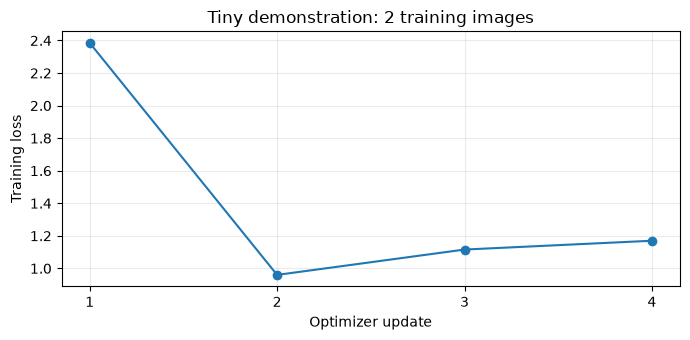

In [46]:
for epoch in range(3):
    epoch_loss = train_epoch(model, train_loader, optimizer, device)
    loss_history.append(epoch_loss)
    print(f"Demo epoch {epoch + 1}: mean loss = {epoch_loss:.4f}")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(range(1, len(loss_history)+1), loss_history, marker="o")
ax.set(xlabel="Optimizer update", ylabel="Training loss", title="Tiny demonstration: 2 training images")
ax.set_xticks(range(1, len(loss_history)+1))
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(RUN_DIR / "loss.png", dpi=140)
plt.show()

In [47]:
def detection_metrics(predictions, targets, iou_threshold=0.5):
    if len(predictions) != len(targets):
        raise ValueError("Each prediction must have a matching target")
    per_class = {}
    for class_id, name in CLASS_NAMES.items():
        ground_truth = [t["boxes"][t["labels"] == class_id].cpu() for t in targets]
        total = sum(len(boxes) for boxes in ground_truth)
        candidates = []
        for image_id, prediction in enumerate(predictions):
            mask = prediction["labels"] == class_id
            for score, box in zip(prediction["scores"][mask], prediction["boxes"][mask]):
                candidates.append((float(score), image_id, box.cpu()))
        candidates.sort(key=lambda item: item[0], reverse=True)
        matched = [set() for _ in targets]
        tp, fp = [], []
        for _, image_id, box in candidates:
            boxes = ground_truth[image_id]
            correct = False
            if len(boxes):
                overlaps = box_iou(box.unsqueeze(0), boxes)[0]
                overlap, match = overlaps.max(dim=0)
                match = int(match)
                if float(overlap) >= iou_threshold and match not in matched[image_id]:
                    matched[image_id].add(match)
                    correct = True
            tp.append(int(correct))
            fp.append(int(not correct))
        ap = None
        if total:
            true_positives = torch.tensor(tp, dtype=torch.float64).cumsum(0)
            false_positives = torch.tensor(fp, dtype=torch.float64).cumsum(0)
            recall = true_positives / total
            precision = true_positives / (true_positives + false_positives).clamp(min=1)
            recall = torch.cat((torch.tensor([0.]), recall, torch.tensor([1.])))
            precision = torch.cat((torch.tensor([0.]), precision, torch.tensor([0.])))
            precision = precision.flip(0).cummax(0).values.flip(0)
            ap = float(((recall[1:] - recall[:-1]) * precision[1:]).sum())
        per_class[name] = {"ap50": ap, "ground_truth": total,
                           "predictions": len(candidates)}
    values = [item["ap50"] for item in per_class.values() if item["ap50"] is not None]
    return {"map50": sum(values) / len(values) if values else 0.0,
            "images": len(targets), "per_class": per_class}


In [48]:
model.eval()
val_predictions, val_targets = [], []
with torch.inference_mode():
    for images, targets in val_loader:
        outputs = model([image.to(device) for image in images])
        val_predictions.extend({key: value.cpu() for key, value in output.items()} for output in outputs)
        val_targets.extend(targets)
metrics = detection_metrics(val_predictions, val_targets)
print(json.dumps(metrics, indent=2))

{
  "map50": 0.6722751322751322,
  "images": 2,
  "per_class": {
    "Open": {
      "ap50": 0.3214285714285714,
      "ground_truth": 2,
      "predictions": 47
    },
    "Short": {
      "ap50": 0.5,
      "ground_truth": 1,
      "predictions": 39
    },
    "Mousebite": {
      "ap50": 0.5955555555555555,
      "ground_truth": 3,
      "predictions": 35
    },
    "Spur": {
      "ap50": 0.6666666666666666,
      "ground_truth": 3,
      "predictions": 32
    },
    "Copper": {
      "ap50": 1.0,
      "ground_truth": 3,
      "predictions": 26
    },
    "Pin hole": {
      "ap50": 0.95,
      "ground_truth": 4,
      "predictions": 18
    }
  }
}


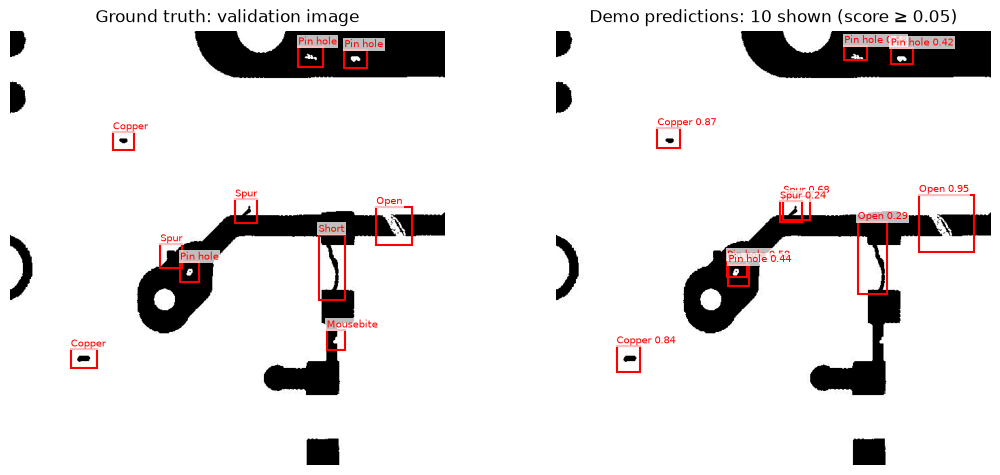

In [49]:
val_image, val_target = demo_val[0]
prediction = val_predictions[0]
display_threshold = 0.05
indices = torch.where(prediction["scores"] >= display_threshold)[0]
indices = indices[prediction["scores"][indices].argsort(descending=True)][:10]
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
show_boxes(axes[0], val_image, val_target["boxes"], val_target["labels"], "Ground truth: validation image")
show_boxes(axes[1], val_image, prediction["boxes"][indices], prediction["labels"][indices],
           f"Demo predictions: {len(indices)} shown (score ≥ {display_threshold})", prediction["scores"][indices])
fig.subplots_adjust(left=0.03, right=0.97, bottom=0.06, top=0.85, wspace=0.12)
fig.savefig(RUN_DIR / "predictions.png", dpi=140)
plt.show()

In [50]:
checkpoint_path = RUN_DIR / "learning_demo.pt"
config = {"learning_demo": True, "image_size": 320, "train_images": len(demo_train),
          "validation_images": len(demo_val), "optimizer_updates": len(loss_history),
          "device": str(device), "seed": 42, "architecture": "fasterrcnn_mobilenet_v3_large_320_fpn"}
torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
            "config": config, "classes": CLASS_NAMES, "metrics": metrics}, checkpoint_path)
(RUN_DIR / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
(RUN_DIR / "split.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
(RUN_DIR / "metrics.json").write_text(json.dumps({"loss_history": loss_history, "validation": metrics}, indent=2), encoding="utf-8")
print("Saved checkpoint:", checkpoint_path)
print("Saved plots: annotations.png, loss.png, predictions.png")

Saved checkpoint: c:\Users\JT GAMING\Desktop\Model working\working_model\outputs\notebooks\learning-20261014-041308-553200\learning_demo.pt
Saved plots: annotations.png, loss.png, predictions.png


In [51]:
saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
restored = build_detector(pretrained=False, image_size=saved["config"]["image_size"])
print(restored.load_state_dict(saved["model"]))
restored.eval()
with torch.inference_mode():
    restored_prediction = restored([val_image])[0]
assert torch.isfinite(restored_prediction["boxes"]).all()
assert set(restored_prediction["labels"].tolist()).issubset(set(CLASS_NAMES))
print("Reloaded detector produced", len(restored_prediction["boxes"]), "candidate detections.")
print("All notebook steps completed. This is still a demonstration model.")

<All keys matched successfully>
Reloaded detector produced 100 candidate detections.
All notebook steps completed. This is still a demonstration model.
